# Lab Benchmark: JEV + LLM vs Native LLM
So sánh hiệu suất giữa 2 cách tiếp cận:
1. **JEV + LLM**: JEV phân loại `intent` (với confident score), nếu `> 0.8` thì gọi Gemini để suy luận `target_tool`.
2. **Native LLM**: Gemini xử lý tất cả (đưa ra `intent`, `target_tool` và `confidence_score`), chỉ hành động nếu `confidence > 0.8`.

Các chỉ số đo lường:
- **Độ trễ (Latency)**
- **Tokens và Cost (Chi phí)**
- **Accuracy / Agreement Rate (%)** với Ground Truth.


In [1]:
import json
import time
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

# Dùng thư viện google.generativeai
import google.generativeai as genai

load_dotenv()
jev_api = os.getenv("jev_api")
gemini_api = os.getenv("gemini_api")

if not jev_api or not gemini_api:
    print("⚠️ Cảnh báo: Thiếu API keys (jev_api hoặc gemini_api) trong .env!")
else:
    print("✅ Load API keys thành công!")

# Khởi tạo client cho Gemini
genai.configure(api_key=gemini_api)
model = genai.GenerativeModel('gemini-2.5-flash')


✅ Load API keys thành công!


/var/folders/nw/ybsx8w3d4rq48myr07lzz2hr0000gn/T/ipykernel_88817/949116493.py:10: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  import google.generativeai as genai


In [2]:
# Đọc dữ liệu từ multihop.json
data = []
with open('multihop.json', 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            data.append(json.loads(line))

print(f"✅ Đã tải {len(data)} mẫu dữ liệu từ multihop.json")

# Liệt kê các intents và tools (làm criteria)
all_intents = ['update_project_status', 'rag_doc_search', 'chitchat_direct_answer', 'escalate_issue', 'reject_access_denied', 'execute_code_sandbox']
all_tools = ['deny_sensitive_data_access', 'escalate_incident', 'knowledge_search', 'escalate_approval_request', 'project_task_update', 'escalate_policy_conflict', 'none', 'python_data_sandbox']


✅ Đã tải 20 mẫu dữ liệu từ multihop.json


In [3]:
# Cấu hình tính phí giả định (USD trên 1M tokens)
JEV_PRICE_IN = 0.042
JEV_PRICE_OUT = 0.0
GEMINI_PRICE_IN = 0.375
GEMINI_PRICE_OUT = 1.875


In [4]:
def call_jev_intent(state_text):
    url = "https://api.typesafe.ai/v1/systemone"
    headers = {
        "Authorization": f"Bearer {jev_api}",
        "Content-Type": "application/json"
    }
    criteria = {intent: intent for intent in all_intents}
    payload = {
        "state": state_text,
        "model": "jev-latest",
        "questions": {
            "intent": {
                "type": "choice",
                "instructions": "Phân loại intent của tin nhắn dựa trên ngữ cảnh.",
                "criteria": criteria
            }
        }
    }
    
    start_time = time.time()
    try:
        res = requests.post(url, headers=headers, json=payload, timeout=30)
        res.raise_for_status()
        resp_data = res.json()
        latency = time.time() - start_time
        answer = resp_data["answers"]["intent"]["choice"]
        confidence = resp_data["answers"]["intent"]["confidence"]
        in_tokens = resp_data["usage"]["input_tokens"]
        out_tokens = resp_data["usage"]["output_tokens"]
        return answer, confidence, latency, in_tokens, out_tokens, None
    except Exception as e:
        return None, 0.0, time.time() - start_time, 0, 0, str(e)

def call_gemini_tool(state_text, intent):
    prompt = f"""Ngữ cảnh và tin nhắn:
{state_text}

Đã được phân loại Intent là: {intent}
Hãy suy luận và chọn ra 1 target_tool phù hợp nhất từ danh sách sau:
{all_tools}

Chỉ trả về tên target_tool, không giải thích thêm.
"""
    start_time = time.time()
    try:
        response = model.generate_content(prompt)
        latency = time.time() - start_time
        target_tool = response.text.strip()
        in_tokens = response.usage_metadata.prompt_token_count
        out_tokens = response.usage_metadata.candidates_token_count
        return target_tool, latency, in_tokens, out_tokens, None
    except Exception as e:
        return None, time.time() - start_time, 0, 0, str(e)

def call_native_llm(state_text):
    prompt = f"""Ngữ cảnh và tin nhắn:
{state_text}

Nhiệm vụ:
1. Phân loại Intent (chọn 1 trong các intent: {all_intents})
2. Xác định target_tool (chọn 1 trong các tool: {all_tools})
3. Đánh giá confidence_score (từ 0.0 đến 1.0) cho quyết định của bạn.

Trả về kết quả chuẩn định dạng JSON sau, không bọc bởi ký tự markdown:
{{
    "intent": "...",
    "target_tool": "...",
    "confidence_score": 0.95
}}
"""
    start_time = time.time()
    try:
        response = model.generate_content(
            prompt,
            generation_config=genai.types.GenerationConfig(
                response_mime_type="application/json"
            )
        )
        latency = time.time() - start_time
        try:
            resp_json = json.loads(response.text)
            intent = resp_json.get("intent", "none")
            target_tool = resp_json.get("target_tool", "none")
            confidence_score = float(resp_json.get("confidence_score", 0.0))
        except:
            intent, target_tool, confidence_score = "error", "error", 0.0
            
        in_tokens = response.usage_metadata.prompt_token_count
        out_tokens = response.usage_metadata.candidates_token_count
        return intent, target_tool, confidence_score, latency, in_tokens, out_tokens, None
    except Exception as e:
        return None, None, 0.0, time.time() - start_time, 0, 0, str(e)


In [5]:
results = []
for item in data:
    context = item["context"]
    state_text = json.dumps(context, ensure_ascii=False, indent=2)
    
    ground_truth_intent = item["output"]["intent"]
    ground_truth_tool = item["output"].get("action_payload", {}).get("target_tool", "none")
    results.append({
        "id": item["id"],
        "state_text": state_text,
        "gt_intent": ground_truth_intent,
        "gt_tool": ground_truth_tool
    })

print("🚀 Bắt đầu benchmark Pipeline 1: JEV + LLM...")
for idx, r in enumerate(results):
    jev_intent, jev_conf, jev_lat, jev_in, jev_out, jev_err = call_jev_intent(r["state_text"])
    if jev_err:
        print(f"  [ERROR JEV] {r['id']}: {jev_err}")
    time.sleep(0.5)
    
    gemini_tool, gemini_lat, gemini_in, gemini_out, gemini_err = "skipped", 0.0, 0, 0, None
    if jev_conf and jev_conf > 0.8:
        gemini_tool, gemini_lat, gemini_in, gemini_out, gemini_err = call_gemini_tool(r["state_text"], jev_intent)
        if gemini_err:
            print(f"  [ERROR Gemini Tool] {r['id']}: {gemini_err}")
        time.sleep(1.0)
        
    pipeline1_intent = jev_intent if jev_conf > 0.8 else "skipped"
    pipeline1_tool = gemini_tool
    pipeline1_lat = jev_lat + gemini_lat
    pipeline1_cost = (jev_in * JEV_PRICE_IN / 1e6) + (gemini_in * GEMINI_PRICE_IN / 1e6) + (gemini_out * GEMINI_PRICE_OUT / 1e6)
    
    r.update({
        "p1_intent": pipeline1_intent,
        "p1_tool": pipeline1_tool,
        "p1_conf": jev_conf,
        "p1_latency": pipeline1_lat,
        "p1_cost": pipeline1_cost,
        "p1_in_tokens": jev_in + gemini_in,
        "p1_out_tokens": jev_out + gemini_out,
    })
    print(f"✅ Đã xử lý Pipeline 1 - {idx+1}/{len(results)} - {r['id']}")

print("\n🚀 Bắt đầu benchmark Pipeline 2: Native LLM...")
for idx, r in enumerate(results):
    native_intent, native_tool, native_conf, native_lat, native_in, native_out, native_err = call_native_llm(r["state_text"])
    if native_err:
        print(f"  [ERROR Native LLM] {r['id']}: {native_err}")
    time.sleep(1.0)
    
    pipeline2_intent = native_intent if native_conf > 0.8 else "skipped"
    pipeline2_tool = native_tool if native_conf > 0.8 else "skipped"
    pipeline2_cost = (native_in * GEMINI_PRICE_IN / 1e6) + (native_out * GEMINI_PRICE_OUT / 1e6)
    
    r.update({
        "p2_intent": pipeline2_intent,
        "p2_tool": pipeline2_tool,
        "p2_conf": native_conf,
        "p2_latency": native_lat,
        "p2_cost": pipeline2_cost,
        "p2_in_tokens": native_in,
        "p2_out_tokens": native_out
    })
    print(f"✅ Đã xử lý Pipeline 2 - {idx+1}/{len(results)} - {r['id']}")

df_results = pd.DataFrame(results)
print("\n🎉 Benchmark hoàn thành!")


🚀 Bắt đầu benchmark Pipeline 1: JEV + LLM...
✅ Đã xử lý Pipeline 1 - 1/20 - SYN_MH_001
✅ Đã xử lý Pipeline 1 - 2/20 - SYN_MH_002
✅ Đã xử lý Pipeline 1 - 3/20 - SYN_MH_003
✅ Đã xử lý Pipeline 1 - 4/20 - SYN_MH_004
✅ Đã xử lý Pipeline 1 - 5/20 - SYN_MH_005
✅ Đã xử lý Pipeline 1 - 6/20 - SYN_MH_006
✅ Đã xử lý Pipeline 1 - 7/20 - SYN_MH_007
✅ Đã xử lý Pipeline 1 - 8/20 - SYN_MH_008
✅ Đã xử lý Pipeline 1 - 9/20 - SYN_MH_009
✅ Đã xử lý Pipeline 1 - 10/20 - SYN_MH_010
✅ Đã xử lý Pipeline 1 - 11/20 - SYN_MH_011
  [ERROR Gemini Tool] SYN_MH_012: 403 Spend cap breached for project: projects/174618899537 for service: generativelanguage.googleapis.com. Correlation id: 4648908153777105964
✅ Đã xử lý Pipeline 1 - 12/20 - SYN_MH_012
✅ Đã xử lý Pipeline 1 - 13/20 - SYN_MH_013
✅ Đã xử lý Pipeline 1 - 14/20 - SYN_MH_014
✅ Đã xử lý Pipeline 1 - 15/20 - SYN_MH_015
✅ Đã xử lý Pipeline 1 - 16/20 - SYN_MH_016
✅ Đã xử lý Pipeline 1 - 17/20 - SYN_MH_017
✅ Đã xử lý Pipeline 1 - 18/20 - SYN_MH_018
✅ Đã xử lý Pip

In [6]:
# Tính toán các chỉ số (Metrics)
total_samples = len(df_results)

# Accuracy (Ý định và Công cụ)
df_results["p1_intent_correct"] = df_results["p1_intent"] == df_results["gt_intent"]
df_results["p1_tool_correct"] = df_results["p1_tool"] == df_results["gt_tool"]
df_results["p1_both_correct"] = df_results["p1_intent_correct"] & df_results["p1_tool_correct"]

df_results["p2_intent_correct"] = df_results["p2_intent"] == df_results["gt_intent"]
df_results["p2_tool_correct"] = df_results["p2_tool"] == df_results["gt_tool"]
df_results["p2_both_correct"] = df_results["p2_intent_correct"] & df_results["p2_tool_correct"]

p1_acc_intent = df_results["p1_intent_correct"].mean() * 100
p1_acc_tool = df_results["p1_tool_correct"].mean() * 100
p1_acc_both = df_results["p1_both_correct"].mean() * 100

p2_acc_intent = df_results["p2_intent_correct"].mean() * 100
p2_acc_tool = df_results["p2_tool_correct"].mean() * 100
p2_acc_both = df_results["p2_both_correct"].mean() * 100

# Trễ và chi phí trung bình
p1_avg_latency = df_results["p1_latency"].mean()
p2_avg_latency = df_results["p2_latency"].mean()

p1_avg_cost = df_results["p1_cost"].mean()
p2_avg_cost = df_results["p2_cost"].mean()
p1_total_cost = df_results["p1_cost"].sum()
p2_total_cost = df_results["p2_cost"].sum()

print("================ TỔNG KẾT BÁO CÁO ================")
print(f"JEV + LLM   | Độ chính xác tổng hợp (Cả Intent & Tool): {p1_acc_both:.2f}%")
print(f"Native LLM  | Độ chính xác tổng hợp (Cả Intent & Tool): {p2_acc_both:.2f}%")
print("--------------------------------------------------")
print(f"JEV + LLM   | Trễ trung bình: {p1_avg_latency:.2f}s | Chi phí tổng: ${p1_total_cost:.6f}")
print(f"Native LLM  | Trễ trung bình: {p2_avg_latency:.2f}s | Chi phí tổng: ${p2_total_cost:.6f}")
print("==================================================")


================ TỔNG KẾT BÁO CÁO ================
JEV + LLM   | Độ chính xác tổng hợp (Cả Intent & Tool): 65.00%
Native LLM  | Độ chính xác tổng hợp (Cả Intent & Tool): 95.00%
--------------------------------------------------
JEV + LLM   | Trễ trung bình: 2.15s | Chi phí tổng: $0.005653
Native LLM  | Trễ trung bình: 4.68s | Chi phí tổng: $0.009470


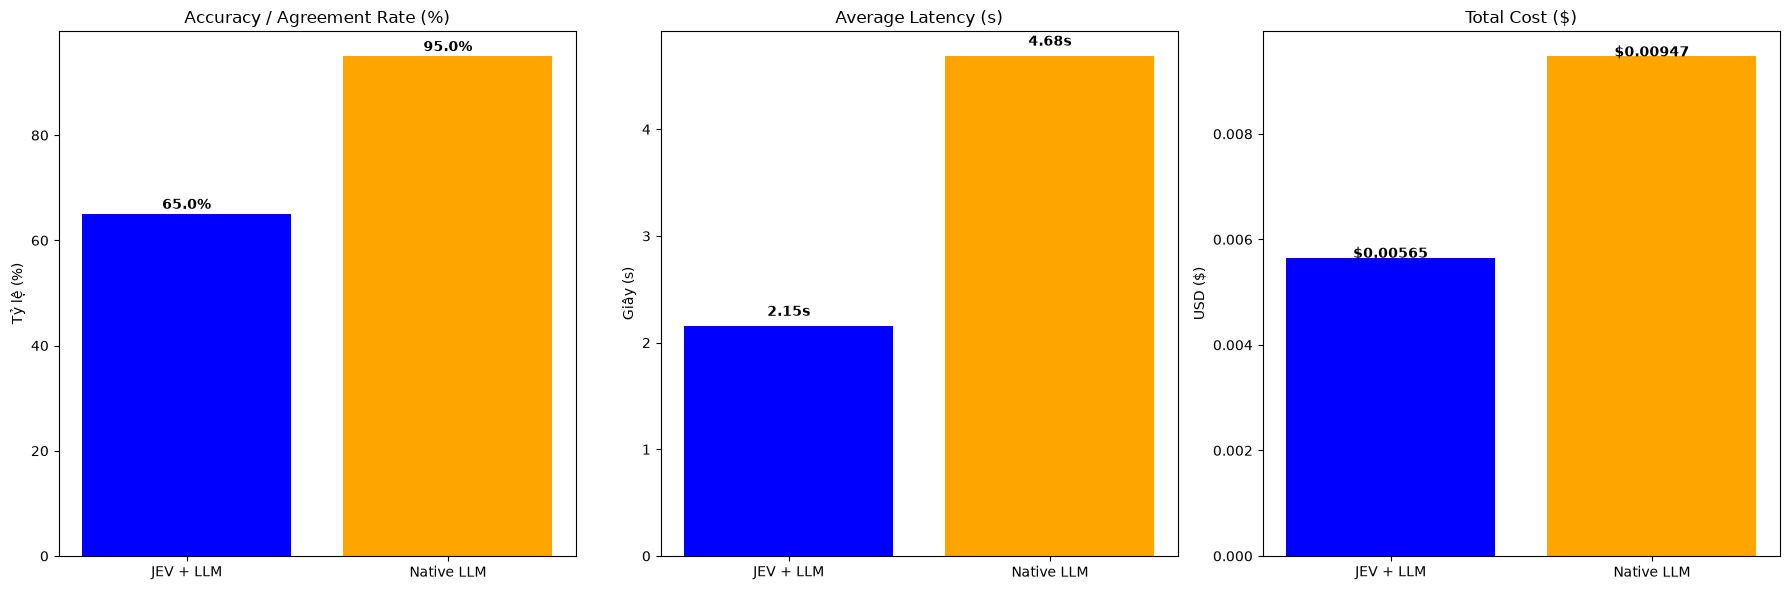

In [7]:
# Vẽ biểu đồ so sánh 3 chỉ số

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

labels = ['JEV + LLM', 'Native LLM']

# 1. Accuracy
acc_data = [p1_acc_both, p2_acc_both]
axes[0].bar(labels, acc_data, color=['blue', 'orange'])
axes[0].set_title('Accuracy / Agreement Rate (%)')
axes[0].set_ylabel('Tỷ lệ (%)')
for i, v in enumerate(acc_data):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

# 2. Latency
lat_data = [p1_avg_latency, p2_avg_latency]
axes[1].bar(labels, lat_data, color=['blue', 'orange'])
axes[1].set_title('Average Latency (s)')
axes[1].set_ylabel('Giây (s)')
for i, v in enumerate(lat_data):
    axes[1].text(i, v + 0.1, f"{v:.2f}s", ha='center', fontweight='bold')

# 3. Cost
cost_data = [p1_total_cost, p2_total_cost]
axes[2].bar(labels, cost_data, color=['blue', 'orange'])
axes[2].set_title('Total Cost ($)')
axes[2].set_ylabel('USD ($)')
for i, v in enumerate(cost_data):
    axes[2].text(i, v, f"${v:.5f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('benchmark_charts.png')
plt.show()
